# CNN para classificação dos escores de Gardner em blastocistos

Este notebook treina uma CNN multi-tarefa (multi-output), com backbone EfficientNetB0 pré-treinado no ImageNet, que recebe uma imagem estática de um blastocisto humano (dia 5 pós-inseminação) e prevê os três critérios do sistema de Gardner usados na seleção de embriões para transferência em FIV:

- **EXP** — grau de expansão/eclosão (ordinal, 5 classes: 0–4)
- **ICM** — qualidade da massa celular interna (ordinal, graus 0–2; classe 3 = não determinado)
- **TE** — qualidade do trofectoderma (ordinal, graus 0–2; classe 3 = não determinado)

A classe 3 do treino corresponde exatamente às imagens com EXP < 2, equivalente ao `ND` do teste gold (verificado na seção 2).

Dados: Kromp et al. (2023, *Sci Data*), em `data/images/`, `data/Gardner_train_silver.csv` (rótulos de um único especialista) e `data/Gardner_test_gold_onlyGardnerScores.csv` (rótulos de consenso de um consórcio — usado só como benchmark final).

## 1. Setup e imports

Requer `tensorflow` e `scikit-learn` instalados no `.venv` local (ver `requirements.txt`). Ambiente sem GPU — o treinamento roda em CPU.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report, cohen_kappa_score

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = "data"
IMAGES_DIR = os.path.join(DATA_DIR, "images")
TRAIN_CSV = os.path.join(DATA_DIR, "Gardner_train_silver.csv")
TEST_CSV = os.path.join(DATA_DIR, "Gardner_test_gold_onlyGardnerScores.csv")

MODELS_DIR = "models"
os.makedirs(MODELS_DIR, exist_ok=True)

IMG_HEIGHT, IMG_WIDTH = 168, 224  # mantém a proporção 4:3 da imagem original (512 de largura x 384 de altura)
BATCH_SIZE = 32

N_EXP, N_ICM, N_TE = 5, 4, 4

# Paleta consistente para os três alvos ao longo do notebook
TARGET_COLORS = {"EXP": "#4C72B0", "ICM": "#DD8452", "TE": "#55A868"}
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

I0000 00:00:1793672805.436193   72100 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793672805.443432   72100 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793672805.478590   72100 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793672806.308361   72100 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793672806.308907   72100 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. Carga e exploração dos CSVs

In [2]:
train_df = pd.read_csv(TRAIN_CSV, sep=";")
train_df = train_df.rename(columns={"EXP_silver": "EXP", "ICM_silver": "ICM", "TE_silver": "TE"})

test_df = pd.read_csv(TEST_CSV, sep=";")
test_df = test_df.drop(columns=[c for c in test_df.columns if c.startswith("Unnamed")])
test_df = test_df.rename(columns={"EXP_gold": "EXP", "ICM_gold": "ICM", "TE_gold": "TE"})

# embryo_id = prefixo antes do "_" no nome do arquivo (ex: "0175_05.png" -> "0175")
train_df["embryo_id"] = train_df["Image"].str.extract(r"^(.+)_\d+\.png$")
test_df["embryo_id"] = test_df["Image"].str.extract(r"^(.+)_\d+\.png$")

print("Treino (silver):", train_df.shape, "| embriões únicos:", train_df["embryo_id"].nunique())
print("Teste (gold):", test_df.shape, "| embriões únicos:", test_df["embryo_id"].nunique())
display(train_df.head())
display(test_df.head())

Treino (silver): (2044, 5) | embriões únicos: 802
Teste (gold): (300, 5) | embriões únicos: 249


,Image,EXP,ICM,TE,embryo_id
0,0175_05.png,3,1,1,0175
1,420_02.png,3,0,0,420
2,680_01.png,2,0,0,680
3,340_03.png,3,0,1,340
4,571_02.png,0,3,3,571


,Image,EXP,ICM,TE,embryo_id
0,0004_03.png,2.0,1,1,0004
1,0005_08.png,3.0,0,0,0005
2,0008_01.png,2.0,0,0,0008
3,0011_02.png,0.0,ND,ND,0011
4,0011_03.png,3.0,1,0,0011


In [3]:
# ICM/TE só podem ser avaliados a partir de EXP >= 2.
# No silver, a classe 3 marca exatamente as imagens não avaliáveis; no gold, elas aparecem como "ND".
for target in ["ICM", "TE"]:
    assert ((train_df[target] == 3) == (train_df["EXP"] < 2)).all()
    assert ((test_df[target] == "ND") == (test_df["EXP"] < 2)).all()
    print(f"{target}: classe 3 no silver = {(train_df[target] == 3).sum()} imagens | ND no gold = {(test_df[target] == 'ND').sum()} imagens")

ICM: classe 3 no silver = 391 imagens | ND no gold = 54 imagens
TE: classe 3 no silver = 391 imagens | ND no gold = 54 imagens


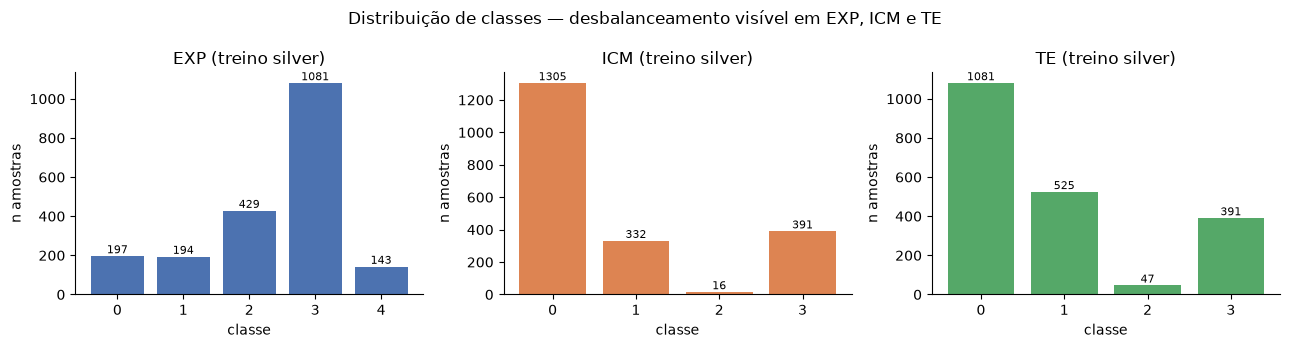

In [4]:
# Distribuição de classes no treino (silver) por alvo
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, target in zip(axes, ["EXP", "ICM", "TE"]):
    counts = train_df[target].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=TARGET_COLORS[target])
    ax.set_title(f"{target} (treino silver)")
    ax.set_xlabel("classe")
    ax.set_ylabel("n amostras")
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
fig.suptitle("Distribuição de classes — desbalanceamento visível em EXP, ICM e TE")
fig.tight_layout()
plt.show()

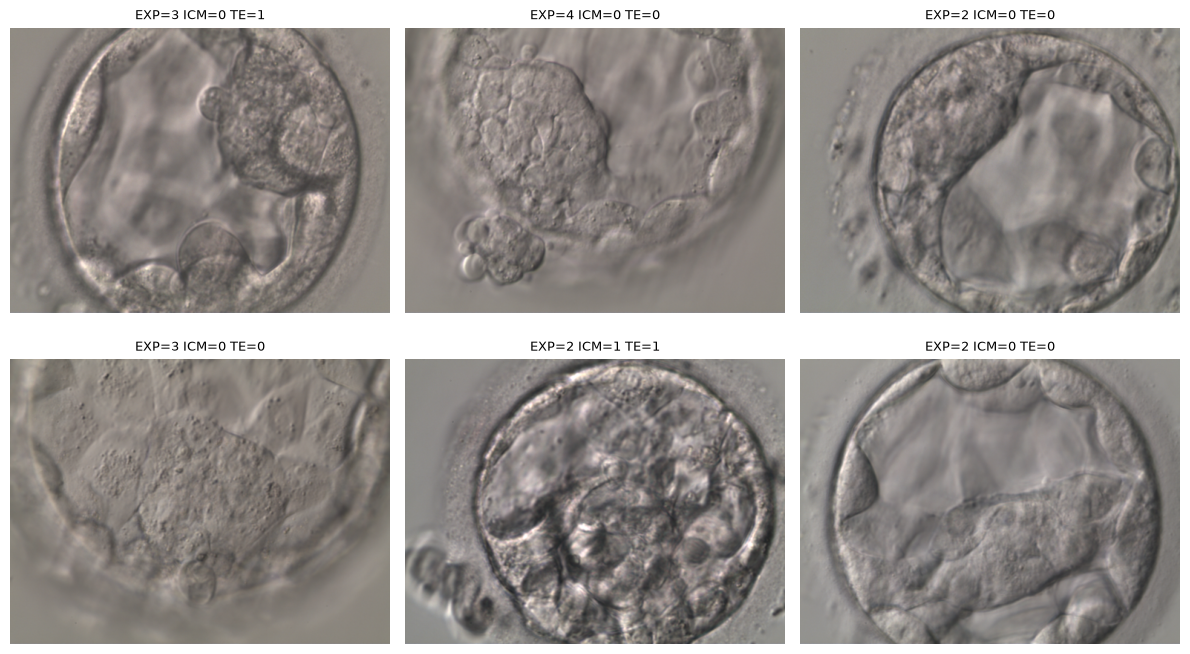

In [5]:
# Exemplos de imagens
from PIL import Image

sample_rows = train_df.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    img = Image.open(os.path.join(IMAGES_DIR, row["Image"]))
    ax.imshow(img)
    ax.set_title(f"EXP={row['EXP']} ICM={row['ICM']} TE={row['TE']}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 3. Split treino/validação por embrião

Usamos `GroupShuffleSplit` agrupando por `embryo_id` para garantir que imagens do mesmo embrião não apareçam simultaneamente em treino e validação (evita vazamento de informação).

In [6]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_idx, val_idx = next(gss.split(train_df, groups=train_df["embryo_id"]))

train_split_df = train_df.iloc[train_idx].reset_index(drop=True)
val_split_df = train_df.iloc[val_idx].reset_index(drop=True)

assert set(train_split_df["embryo_id"]).isdisjoint(set(val_split_df["embryo_id"])), "Vazamento de embriões entre treino e validação!"

print(f"Treino: {len(train_split_df)} imagens / {train_split_df['embryo_id'].nunique()} embriões")
print(f"Validação: {len(val_split_df)} imagens / {val_split_df['embryo_id'].nunique()} embriões")

Treino: 1743 imagens / 681 embriões
Validação: 301 imagens / 121 embriões


## 4. Pipelines `tf.data`

Carregamento/decodificação de PNG, redimensionamento para 224×168 (largura×altura) e normalização para [0,1]. Augmentação (flip horizontal/vertical, rotação ±15°, variação de brilho) é aplicada apenas no conjunto de treino, via camadas `keras.layers` ativas somente em modo de treinamento.

In [7]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(15 / 360),
    layers.RandomBrightness(0.1, value_range=(0, 1)),
], name="augmentation")


def load_image(filename):
    path = tf.strings.join([IMAGES_DIR, filename], separator=os.sep)
    img = tf.io.read_file(path)
    img = tf.io.decode_png(img, channels=3)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    img = img / 255.0
    return img


def make_dataset(df, training, batch_size=BATCH_SIZE):
    # y é uma tupla (EXP, ICM, TE), na mesma ordem das saídas do modelo —
    # passar um dict aqui quebra o Keras 3 quando combinado com sample_weight (ver make_dataset_with_weights)
    filenames = df["Image"].values
    labels = (
        df["EXP"].astype("int32").values,
        df["ICM"].astype("int32").values,
        df["TE"].astype("int32").values,
    )
    ds = tf.data.Dataset.from_tensor_slices((filenames, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)

    def _map(filename, label):
        img = load_image(filename)
        return img, label

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    if training:
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_split_df, training=True)
val_ds = make_dataset(val_split_df, training=False)

# smoke test: confirmar shapes de um lote
images_batch, labels_batch = next(iter(train_ds))
print("Batch de imagens:", images_batch.shape, images_batch.dtype)
for name, v in zip(["EXP", "ICM", "TE"], labels_batch):
    print(f"  {name}: {v.shape} {v.dtype}")

E0000 00:00:1793672807.677328   72100 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Batch de imagens: (32, 168, 224, 3) <dtype: 'float32'>
  EXP: (32,) <dtype: 'int32'>
  ICM: (32,) <dtype: 'int32'>
  TE: (32,) <dtype: 'int32'>


## 5. Definição do modelo: backbone pré-treinado + 3 cabeças

O backbone é uma EfficientNetB0 pré-treinada no ImageNet e congelada, então só as cabeças são treinadas. Essa versão da EfficientNet normaliza a entrada internamente e espera pixels de 0 a 255, por isso a imagem é reescalada antes de entrar nela.

In [8]:
def build_model():
    inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="image")
    x = layers.Rescaling(255.0, name="to_0_255")(inputs)

    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    )
    base.trainable = False
    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)

    exp_output = layers.Dense(N_EXP, activation="softmax", name="exp_output")(x)
    icm_output = layers.Dense(N_ICM, activation="softmax", name="icm_output")(x)
    te_output = layers.Dense(N_TE, activation="softmax", name="te_output")(x)

    return keras.Model(inputs=inputs, outputs=[exp_output, icm_output, te_output], name="gardner_efficientnetb0")


model = build_model()
model.summary()

Model: "gardner_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 168, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_0_255            │ (None, 168, 224,  │          0 │ image[0][0]       │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 6, 7,      │  4,049,571 │ to_0_255[0][0]    │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    327,936 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ exp_output (Dense)  │ (None, 5)         │      1,285 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ icm_output (Dense)  │ (None, 4)         │      1,028 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ te_output (Dense)   │ (None, 4)         │      1,028 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,380,848 (16.71 MB)

 Trainable params: 331,277 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 6. Compilação: losses, loss_weights, métricas, otimizador

In [9]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    # listas na ordem das saídas do modelo (exp, icm, te) — ver nota em make_dataset sobre dicts + sample_weight
    loss=["sparse_categorical_crossentropy", "sparse_categorical_crossentropy", "sparse_categorical_crossentropy"],
    loss_weights=[1.0, 1.0, 1.0],
    metrics=[["accuracy"], ["accuracy"], ["accuracy"]],
)

## 7. Callbacks

In [10]:
CHECKPOINT_PATH = os.path.join(MODELS_DIR, "gardner_cnn.keras")

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True, start_from_epoch=15),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint(CHECKPOINT_PATH, monitor="val_loss", save_best_only=True),
    keras.callbacks.CSVLogger(os.path.join(MODELS_DIR, "training_log.csv")),
]

## 8. Treinamento

Pesos de amostra por alvo (derivados de `compute_class_weight`) compensam o desbalanceamento de classes — o Keras multi-output não aceita um `class_weight` dict por saída diretamente, então convertemos para `sample_weight` por amostra em cada cabeça.

Os pesos são limitados a `MAX_CLASS_WEIGHT`, para que uma única imagem rara não domine o lote.

Em ICM e TE, a classe 3 significa "não determinado" e acontece exatamente quando EXP < 2. Por isso, essas duas saídas treinam só com imagens avaliáveis: a classe 3 recebe peso 0 no treino e na validação. A validação não usa pesos de classe, porque com apenas 4 imagens de ICM=2 cada uma dominaria a `val_loss`.

Com isso, a accuracy de validação de ICM/TE exibida durante o treino inclui imagens de classe 3 que o modelo não aprende a prever. Use as métricas de imagens avaliáveis da seção 10.

In [11]:
MAX_CLASS_WEIGHT = 10.0
UNDETERMINED_TARGETS = ("ICM", "TE")


def sample_weights_for(df, target, n_classes):
    # Em ICM/TE, a classe 3 significa "não determinado": recebe peso 0 e fica fora do cálculo dos demais pesos.
    has_undetermined = target in UNDETERMINED_TARGETS
    classes = np.arange(n_classes - 1 if has_undetermined else n_classes)
    y = df.loc[df[target].isin(classes), target].values
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=y)
    weights = np.minimum(weights, MAX_CLASS_WEIGHT)
    class_to_weight = dict(zip(classes, weights))
    return df[target].map(class_to_weight).fillna(0.0).astype("float32").values


def validation_weights_for(df, target):
    # Sem pesos de classe: só retira das saídas ICM/TE as imagens não determinadas.
    if target in UNDETERMINED_TARGETS:
        return (df[target] != 3).astype("float32").values
    return np.ones(len(df), dtype="float32")


def make_dataset_with_weights(df, training, batch_size=BATCH_SIZE, weights=None):
    filenames = df["Image"].values
    labels = (
        df["EXP"].astype("int32").values,
        df["ICM"].astype("int32").values,
        df["TE"].astype("int32").values,
    )
    if weights is None:
        weights = (
            sample_weights_for(df, "EXP", N_EXP),
            sample_weights_for(df, "ICM", N_ICM),
            sample_weights_for(df, "TE", N_TE),
        )
    ds = tf.data.Dataset.from_tensor_slices((filenames, labels, weights))
    if training:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)

    def _map(filename, label, weight):
        img = load_image(filename)
        return img, label, weight

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    if training:
        ds = ds.map(lambda x, y, w: (augmentation(x, training=True), y, w), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_ds_w = make_dataset_with_weights(train_split_df, training=True)
val_ds_w = make_dataset_with_weights(
    val_split_df,
    training=False,
    weights=tuple(validation_weights_for(val_split_df, target) for target in ["EXP", "ICM", "TE"]),
)

EPOCHS = 60

history = model.fit(
    train_ds_w,
    validation_data=val_ds_w,  # sem pesos de classe; ICM/TE ignoram a classe 3
    epochs=EPOCHS,
    callbacks=callbacks,
)

# O early stopping só considera epochs a partir de start_from_epoch, mas o checkpoint considera todas.
# Salvar aqui garante que o arquivo seja o mesmo modelo avaliado nas próximas seções.
model.save(CHECKPOINT_PATH)

Epoch 1/60


/home/romano/projects/iaga04/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/55 ━━━━━━━━━━━━━━━━━━━━ 5:31 6s/step - exp_output_accuracy: 0.2812 - exp_output_loss: 1.1737 - icm_output_accuracy: 0.1875 - icm_output_loss: 0.9625 - loss: 2.9506 - te_output_accuracy: 0.4062 - te_output_loss: 0.8144

 2/55 ━━━━━━━━━━━━━━━━━━━━ 15s 294ms/step - exp_output_accuracy: 0.2188 - exp_output_loss: 1.5747 - icm_output_accuracy: 0.2344 - icm_output_loss: 0.9977 - loss: 3.6328 - te_output_accuracy: 0.3438 - te_output_loss: 1.0603

 3/55 ━━━━━━━━━━━━━━━━━━━━ 15s 289ms/step - exp_output_accuracy: 0.1771 - exp_output_loss: 1.8309 - icm_output_accuracy: 0.2500 - icm_output_loss: 0.8592 - loss: 3.6059 - te_output_accuracy: 0.3438 - te_output_loss: 0.9158

 4/55 ━━━━━━━━━━━━━━━━━━━━ 14s 290ms/step - exp_output_accuracy: 0.1562 - exp_output_loss: 1.6922 - icm_output_accuracy: 0.2266 - icm_output_loss: 1.0551 - loss: 3.6257 - te_output_accuracy: 0.3672 - te_output_loss: 0.8784

... (2,556 outputs left out)

53/55 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - exp_output_accuracy: 0.6899 - exp_output_loss: 0.6403 - icm_output_accuracy: 0.5884 - icm_output_loss: 0.3179 - loss: 1.3550 - te_output_accuracy: 0.5743 - te_output_loss: 0.3967

54/55 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - exp_output_accuracy: 0.6875 - exp_output_loss: 0.6407 - icm_output_accuracy: 0.5885 - icm_output_loss: 0.3182 - loss: 1.3547 - te_output_accuracy: 0.5764 - te_output_loss: 0.3957

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - exp_output_accuracy: 0.6856 - exp_output_loss: 0.6354 - icm_output_accuracy: 0.5875 - icm_output_loss: 0.3203 - loss: 1.3516 - te_output_accuracy: 0.5766 - te_output_loss: 0.3925

55/55 ━━━━━━━━━━━━━━━━━━━━ 20s 356ms/step - exp_output_accuracy: 0.6856 - exp_output_loss: 0.6354 - icm_output_accuracy: 0.5875 - icm_output_loss: 0.3203 - loss: 1.3516 - te_output_accuracy: 0.5766 - te_output_loss: 0.3925 - val_exp_output_accuracy: 0.6512 - val_exp_output_loss: 0.7936 - val_icm_output_accuracy: 0.5814 - val_icm_output_loss: 0.5696 - val_loss: 1.9866 - val_te_output_accuracy: 0.5482 - val_te_output_loss: 0.6274 - learning_rate: 1.8750e-05


## 9. Curvas de treino

A loss de treino usa pesos de classe e a de validação não, então compare a tendência de cada curva, não o valor absoluto entre elas.

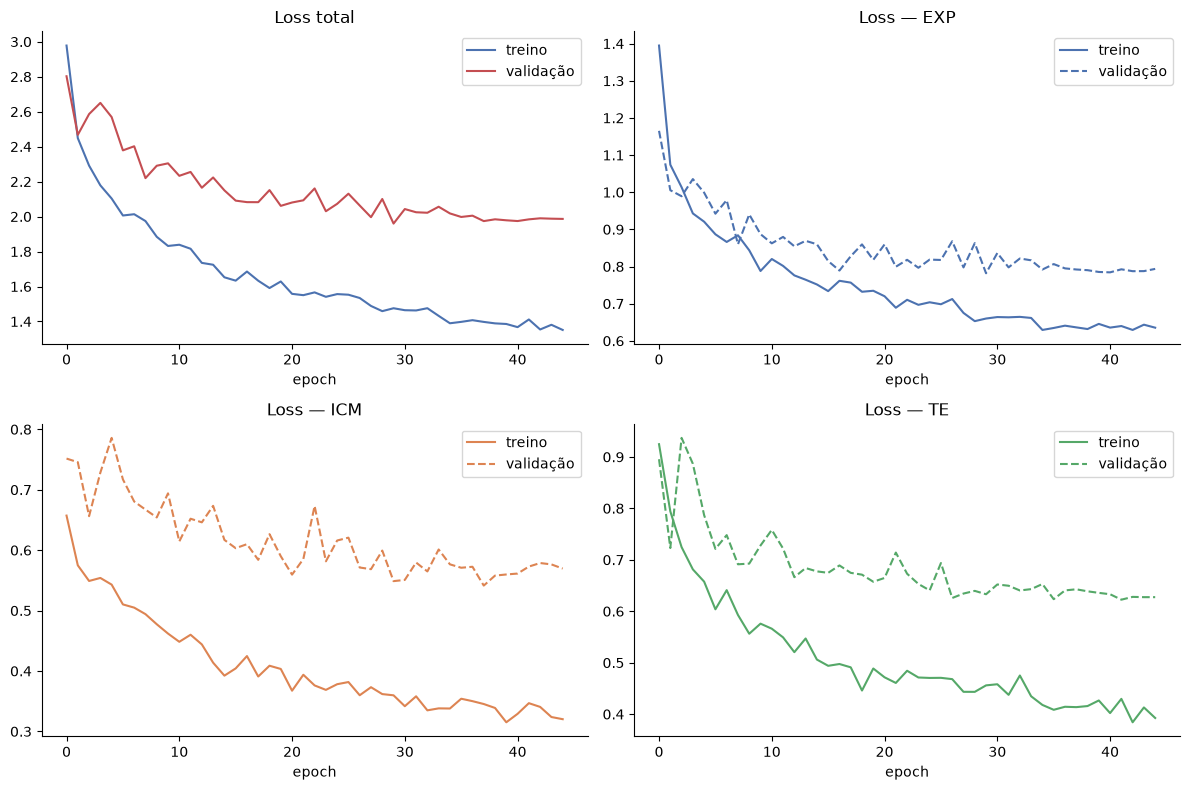

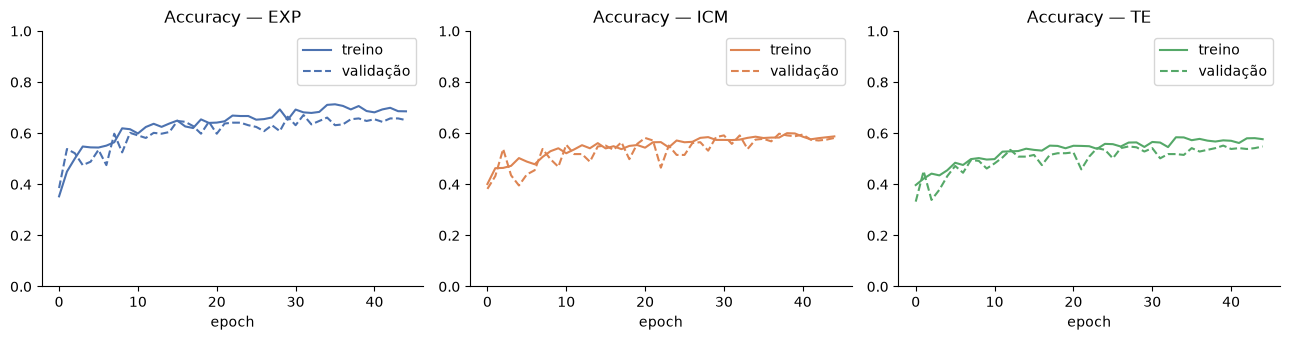

In [12]:
hist_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(hist_df["loss"], label="treino", color="#4C72B0")
axes[0, 0].plot(hist_df["val_loss"], label="validação", color="#C44E52")
axes[0, 0].set_title("Loss total")
axes[0, 0].set_xlabel("epoch")
axes[0, 0].legend()

for ax, target in zip(axes.flat[1:], ["exp", "icm", "te"]):
    loss_col = f"{target}_output_loss"
    val_loss_col = f"val_{target}_output_loss"
    ax.plot(hist_df[loss_col], label="treino", color=TARGET_COLORS[target.upper()])
    ax.plot(hist_df[val_loss_col], label="validação", linestyle="--", color=TARGET_COLORS[target.upper()])
    ax.set_title(f"Loss — {target.upper()}")
    ax.set_xlabel("epoch")
    ax.legend()

fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, target in zip(axes, ["exp", "icm", "te"]):
    acc_col = f"{target}_output_accuracy"
    val_acc_col = f"val_{target}_output_accuracy"
    ax.plot(hist_df[acc_col], label="treino", color=TARGET_COLORS[target.upper()])
    ax.plot(hist_df[val_acc_col], label="validação", linestyle="--", color=TARGET_COLORS[target.upper()])
    ax.set_title(f"Accuracy — {target.upper()}")
    ax.set_xlabel("epoch")
    ax.set_ylim(0, 1)
    ax.legend()
fig.tight_layout()
plt.show()

## 10. Avaliação na validação (silver)

In [13]:
val_results = model.evaluate(val_ds_w, return_dict=True)
print("Avaliação na validação (silver):")
for k, v in val_results.items():
    print(f"  {k}: {v:.4f}")

 1/10 ━━━━━━━━━━━━━━━━━━━━ 3s 366ms/step - exp_output_accuracy: 0.6562 - exp_output_loss: 0.7321 - icm_output_accuracy: 0.6250 - icm_output_loss: 0.4400 - loss: 1.8304 - te_output_accuracy: 0.4688 - te_output_loss: 0.6582

 2/10 ━━━━━━━━━━━━━━━━━━━━ 2s 294ms/step - exp_output_accuracy: 0.6406 - exp_output_loss: 0.8366 - icm_output_accuracy: 0.5938 - icm_output_loss: 0.4512 - loss: 1.9423 - te_output_accuracy: 0.4531 - te_output_loss: 0.6545

 3/10 ━━━━━━━━━━━━━━━━━━━━ 2s 295ms/step - exp_output_accuracy: 0.6250 - exp_output_loss: 0.8723 - icm_output_accuracy: 0.5833 - icm_output_loss: 0.4439 - loss: 1.9804 - te_output_accuracy: 0.4583 - te_output_loss: 0.6642

 4/10 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step - exp_output_accuracy: 0.6484 - exp_output_loss: 0.8861 - icm_output_accuracy: 0.5391 - icm_output_loss: 0.4862 - loss: 2.0174 - te_output_accuracy: 0.4766 - te_output_loss: 0.6450

 5/10 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step - exp_output_accuracy: 0.6625 - exp_output_loss: 0.8630 - icm_output_accuracy: 0.5437 - icm_output_loss: 0.4983 - loss: 2.0171 - te_output_accuracy: 0.4750 - te_output_loss: 0.6557

 6/10 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step - exp_output_accuracy: 0.6667 - exp_output_loss: 0.8476 - icm_output_accuracy: 0.5729 - icm_output_loss: 0.5012 - loss: 1.9950 - te_output_accuracy: 0.4948 - te_output_loss: 0.6461

... (2 outputs left out)

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - exp_output_accuracy: 0.6562 - exp_output_loss: 0.8255 - icm_output_accuracy: 0.5938 - icm_output_loss: 0.5044 - loss: 1.9570 - te_output_accuracy: 0.5312 - te_output_loss: 0.6271

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - exp_output_accuracy: 0.6645 - exp_output_loss: 0.7818 - icm_output_accuracy: 0.5847 - icm_output_loss: 0.5488 - loss: 1.9599 - te_output_accuracy: 0.5282 - te_output_loss: 0.6331

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 265ms/step - exp_output_accuracy: 0.6645 - exp_output_loss: 0.7818 - icm_output_accuracy: 0.5847 - icm_output_loss: 0.5488 - loss: 1.9599 - te_output_accuracy: 0.5282 - te_output_loss: 0.6331


Avaliação na validação (silver):
  exp_output_accuracy: 0.6645
  exp_output_loss: 0.7818
  icm_output_accuracy: 0.5847
  icm_output_loss: 0.5488
  loss: 1.9599
  te_output_accuracy: 0.5282
  te_output_loss: 0.6331


In [14]:
# Métricas por alvo na validação. Em ICM/TE, "avaliáveis" exclui a classe 3 (não determinado),
# como no teste gold, para que a comparação seja justa.
val_preds = model.predict(val_ds.map(lambda x, y: x), verbose=0)

rows = []
for target, probs in zip(["EXP", "ICM", "TE"], val_preds):
    y_true = val_split_df[target].values
    y_pred = probs.argmax(axis=1)
    mask = np.ones(len(y_true), dtype=bool) if target == "EXP" else y_true != 3
    rows.append({
        "alvo": target,
        "n_avaliaveis": int(mask.sum()),
        "accuracy": (y_true[mask] == y_pred[mask]).mean(),
        "linha_de_base": pd.Series(y_true[mask]).value_counts(normalize=True).iloc[0],
        "kappa_quadratico": cohen_kappa_score(y_true[mask], y_pred[mask], weights="quadratic"),
    })
display(pd.DataFrame(rows).round(3))

,alvo,n_avaliaveis,accuracy,linha_de_base,kappa_quadratico
0,EXP,301,0.664,0.558,0.818
1,ICM,251,0.701,0.805,0.350
2,TE,251,0.633,0.665,0.295


## 11. Avaliação no conjunto de teste gold

Para cada alvo, linhas com `'ND'` ou `NaN` *naquele alvo* são descartadas apenas da avaliação daquele alvo (a imagem pode permanecer válida para os outros dois alvos).

Como `ND` equivale à classe 3 do treino, essas métricas medem o grau de ICM/TE apenas nas imagens avaliáveis. Se o modelo prevê a classe 3 em uma dessas imagens, isso conta como erro.

In [15]:
# Predições para todas as imagens do teste gold
test_ds = make_dataset(test_df.assign(EXP=0, ICM=0, TE=0), training=False)  # labels dummy, usados só p/ montar o pipeline
test_images_ds = test_ds.map(lambda x, y: x)
exp_pred, icm_pred, te_pred = model.predict(test_images_ds)

exp_pred_cls = exp_pred.argmax(axis=1)
icm_pred_cls = icm_pred.argmax(axis=1)
te_pred_cls = te_pred.argmax(axis=1)

test_df["EXP_pred"] = exp_pred_cls
test_df["ICM_pred"] = icm_pred_cls
test_df["TE_pred"] = te_pred_cls

 1/10 ━━━━━━━━━━━━━━━━━━━━ 4s 504ms/step

 2/10 ━━━━━━━━━━━━━━━━━━━━ 2s 262ms/step

 3/10 ━━━━━━━━━━━━━━━━━━━━ 1s 262ms/step

 4/10 ━━━━━━━━━━━━━━━━━━━━ 1s 262ms/step

 5/10 ━━━━━━━━━━━━━━━━━━━━ 1s 262ms/step

 6/10 ━━━━━━━━━━━━━━━━━━━━ 1s 262ms/step

 7/10 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step

 8/10 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 246ms/step


In [16]:
def valid_mask(series):
    return series.notna() & (series.astype(str) != "ND")


def evaluate_target(df, target, n_classes):
    mask = valid_mask(df[target])
    y_true = df.loc[mask, target].astype(int).values
    y_pred = df.loc[mask, f"{target}_pred"].values
    n_excluded = (~mask).sum()

    acc = (y_true == y_pred).mean()
    kappa = cohen_kappa_score(y_true, y_pred, weights="quadratic")
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(n_classes))
    report = classification_report(y_true, y_pred, labels=np.arange(n_classes), zero_division=0)

    print(f"=== {target} (gold) ===")
    print(f"n válidos: {mask.sum()} | excluídos (ND/NaN): {n_excluded}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Cohen's Kappa (quadrático): {kappa:.4f}")
    print(report)
    return cm, acc, kappa


results = {}
for target, n_classes in [("EXP", N_EXP), ("ICM", N_ICM), ("TE", N_TE)]:
    results[target] = evaluate_target(test_df, target, n_classes)

=== EXP (gold) ===
n válidos: 298 | excluídos (ND/NaN): 2
Accuracy: 0.7651
Cohen's Kappa (quadrático): 0.8642
              precision    recall  f1-score   support

           0       0.77      0.74      0.76        23
           1       0.47      0.61      0.54        31
           2       0.73      0.73      0.73        86
           3       0.95      0.82      0.88       153
           4       0.21      0.80      0.33         5

    accuracy                           0.77       298
   macro avg       0.63      0.74      0.65       298
weighted avg       0.81      0.77      0.78       298

=== ICM (gold) ===
n válidos: 238 | excluídos (ND/NaN): 62
Accuracy: 0.6176
Cohen's Kappa (quadrático): 0.3293
              precision    recall  f1-score   support

           0       0.79      0.67      0.73       153
           1       0.41      0.65      0.50        68
           2       0.00      0.00      0.00        17
           3       0.00      0.00      0.00         0

    accuracy      

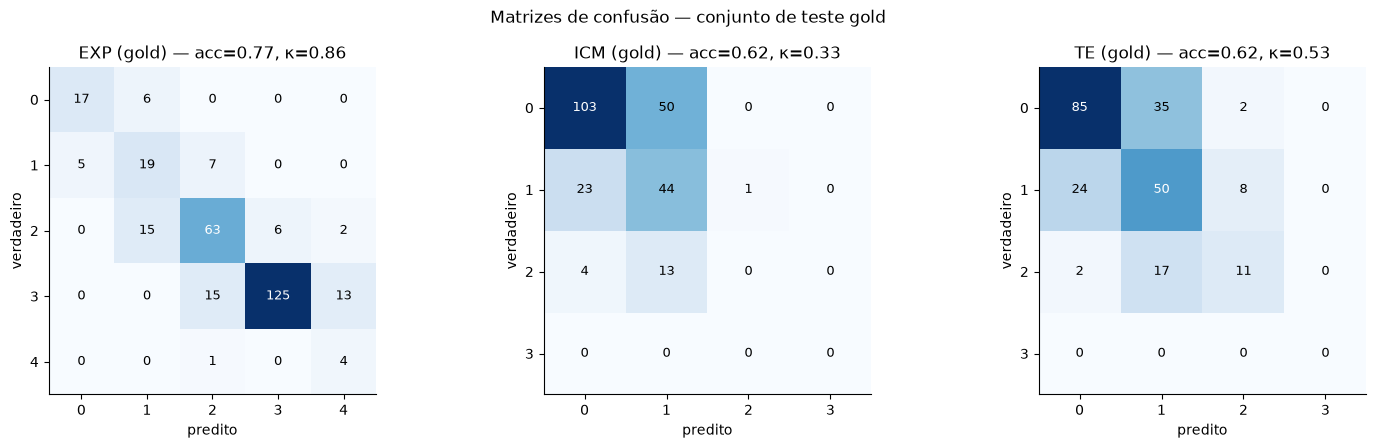

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, target in zip(axes, ["EXP", "ICM", "TE"]):
    cm, acc, kappa = results[target]
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{target} (gold) — acc={acc:.2f}, κ={kappa:.2f}")
    ax.set_xlabel("predito")
    ax.set_ylabel("verdadeiro")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    ax.set_xticks(range(cm.shape[0]))
    ax.set_yticks(range(cm.shape[0]))
fig.suptitle("Matrizes de confusão — conjunto de teste gold")
fig.tight_layout()
plt.show()

### Embriões inéditos no teste gold

Nenhuma imagem de teste aparece no treino, mas a maioria dos embriões do gold tem outras imagens no CSV de treino silver. Isso pode inflar as métricas gerais. A tabela abaixo separa os embriões que têm imagens no silver dos inéditos, que dão a estimativa mais honesta de generalização. Como o subconjunto inédito é pequeno, seus valores têm alta incerteza.

In [18]:
silver_embryos = set(train_df["embryo_id"])
is_unseen = ~test_df["embryo_id"].isin(silver_embryos)
print(f"Imagens gold: {len(test_df)} ({test_df['embryo_id'].nunique()} embriões)")
print(f"Inéditas: {is_unseen.sum()} ({test_df.loc[is_unseen, 'embryo_id'].nunique()} embriões)")


def summarize_subset(df, name):
    rows = []
    for target in ["EXP", "ICM", "TE"]:
        mask = valid_mask(df[target])
        y_true = df.loc[mask, target].astype(int).values
        y_pred = df.loc[mask, f"{target}_pred"].values
        rows.append({
            "subconjunto": name,
            "alvo": target,
            "n": int(mask.sum()),
            "accuracy": (y_true == y_pred).mean(),
            "kappa_quadratico": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
        })
    return rows


subset_results = pd.DataFrame(
    summarize_subset(test_df, "todos")
    + summarize_subset(test_df[~is_unseen], "embrião presente no silver")
    + summarize_subset(test_df[is_unseen], "embrião inédito")
)
display(subset_results.round(3))

Imagens gold: 300 (249 embriões)
Inéditas: 58 (49 embriões)


,subconjunto,alvo,n,accuracy,kappa_quadratico
0,todos,EXP,298,0.765,0.864
1,todos,ICM,238,0.618,0.329
2,todos,TE,234,0.624,0.531
3,embrião presente no silver,EXP,240,0.783,0.884
4,embrião presente no silver,ICM,195,0.621,0.318
5,embrião presente no silver,TE,193,0.622,0.540
6,embrião inédito,EXP,58,0.690,0.798
7,embrião inédito,ICM,43,0.605,0.383
8,embrião inédito,TE,41,0.634,0.480


## 12. Conclusões

**Domain shift silver → gold.** O treino usa rótulos de um único embriologista (silver), enquanto o teste usa consenso de um consórcio internacional (gold). Essa diferença de critério de anotação pode reduzir o desempenho no teste em relação à validação (que é amostrada do próprio conjunto silver): o modelo aprende os padrões de um único anotador, não necessariamente o consenso.

**Embriões compartilhados entre treino e teste.** A maioria dos embriões do gold também tem outras imagens no treino silver, o que pode inflar as métricas gerais. A comparação com os embriões inéditos está na seção 11, com a ressalva de que esse subconjunto é pequeno.

**Classe 3 de ICM/TE.** Essa classe marca imagens não avaliáveis (EXP < 2), não um quarto grau de qualidade. Ela é excluída do treino de ICM/TE e da avaliação no gold. Para saber se uma imagem é avaliável, basta verificar se EXP >= 2.

**Desbalanceamento de classes.** Classes raras (ex.: EXP=4, ICM=2, TE=2) têm poucas amostras no treino. O `sample_weight` balanceado compensa parte disso, mas não cria exemplos novos. O recall dessas classes deve ser conferido nas matrizes de confusão. O Kappa quadrático penaliza menos erros entre classes vizinhas do que erros distantes, por isso é apropriado para essas escalas ordinais.

**Limitações e próximos passos:**
- *Ajuste fino (fine-tuning)* das últimas camadas do backbone pode adaptar melhor as características do ImageNet às imagens de embriões.
- *Ordinal regression* (ex. CORAL/CORN) respeita a ordem natural de EXP e dos graus de ICM/TE, com a classe 3 tratada à parte.
- *Test-time augmentation* (média de predições sobre várias versões aumentadas da mesma imagem) pode reduzir variância nas predições.
- Agregar múltiplas imagens do mesmo embrião (ensembling por embrião) poderia refletir melhor a prática clínica, em que o embriologista normalmente avalia várias vistas antes de decidir.